In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


In [7]:
# -----------------------------
# Load dataset
# -----------------------------
file_path = "C:/Users/hp/Downloads/iris.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [8]:
print(data.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


In [9]:
# -----------------------------
# Separate Features and Target
# -----------------------------
X = data.drop(columns=["species"])


In [10]:
# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()

X_Scaled = scaler.fit_transform(X)
print("\nScaled Features (First 5 rows)")
print(X_Scaled[:5])



Scaled Features (First 5 rows)
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [11]:
# --------------------------------------------------
# 5. Apply DBSCAN clustering
# --------------------------------------------------

dbscan = DBSCAN(eps=0.5,min_samples=5)

y_pred = dbscan.fit_predict(X_Scaled)



In [13]:
# --------------------------------------------------
# 6. Display clustering results
# --------------------------------------------------

n_clusters = len(set(y_pred) - {-1})

n_noise = np.sum(y_pred == -1)

print("\nNumber of clusters:", n_clusters)

print("Number of noise points:", n_noise)

print("\nCluster labels:")
print(np.unique(y_pred))




Number of clusters: 2
Number of noise points: 35

Cluster labels:
[-1  0  1]


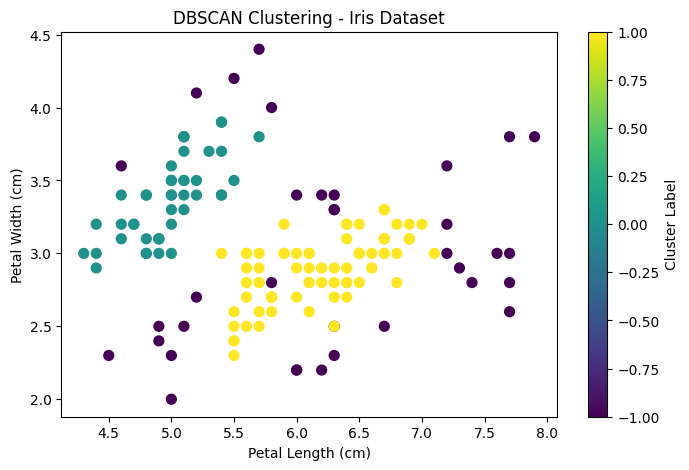

In [14]:
# --------------------------------------------------
# 7. Visualize data AFTER clustering
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=y_pred,
    cmap="viridis",
    s=50
)

plt.title("DBSCAN Clustering - Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.colorbar(label="Cluster Label")

plt.show()



In [ ]:
# --------------------------------------------------
# 8. Calculate Silhouette Score to evaluate the clusters
# --------------------------------------------------

# Exclude noise points
non_noise = y_pred != -1

X_clustered = X_Scaled[non_noise]

labels_clustered = y_pred[non_noise]

if len(np.unique(labels_clustered)) >= 2:

    score = silhouette_score(X_clustered,labels_clustered)

    print("\nSilhouette Score:", round(score, 4))

else:

    print("\nSilhouette Score cannot be calculated.")
    print("At least two non-noise clusters are required.")




Silhouette Score: 0.6532


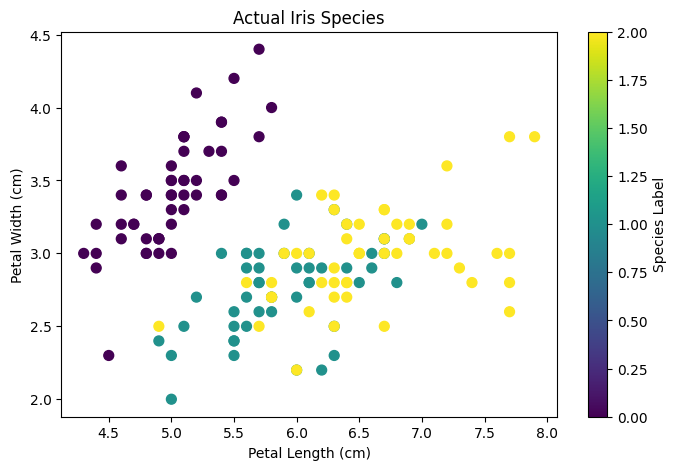

In [16]:
# --------------------------------------------------
# 9. Visualize actual Iris species (optional)
# --------------------------------------------------
# Actual species labels (used only for comparison)
if "Species" in data.columns:
    y_true = data["Species"]

elif "species" in data.columns:
    y_true = data["species"]

else:
    y_true = None


if y_true is not None:

    plt.figure(figsize=(8, 5))

    plt.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=pd.factorize(y_true)[0],
        cmap="viridis",
        s=50
    )

    plt.title("Actual Iris Species")
    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")

    plt.colorbar(label="Species Label")

    plt.show()
